#RCA Activity: Titanic Survival Prediction using Logistic Regression

**Objective:** Predict whether a Titanic passenger survived or did not survive using Logistic Regression.

**Dataset:** [Titanic dataset](https://github.com/mwaskom/seaborn-data/blob/master/titanic.csv)


## 1. Import libraries

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

sns.set_theme(style="whitegrid")

## 2. Load dataset

In [28]:

df = pd.read_csv("titanic.csv")

## 3. Inspect the data

In [29]:
display(df.head())
display(df.tail())
print("Columns:", df.columns.tolist())
df.info()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2

In [30]:
display(df.describe())
display(df.describe(include="object"))

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


## 4. Select features and target

Input features: passenger class, sex, age, siblings/spouses, parents/children, fare and embarkation port.

In [31]:
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]
target = "survived"

data = df[features + [target]].dropna(subset=[target]).copy()
data[target] = data[target].astype(int)

data["family_size"] = data["sibsp"] + data["parch"] + 1
data["is_alone"] = (data["family_size"] == 1).astype(int)

features = features + ["family_size", "is_alone"]
X = data[features]
y = data[target]
print("Selected data shape:", data.shape)
print("Target counts:")
display(y.value_counts())

Selected data shape: (891, 10)
Target counts:


,count
survived,
0,549
1,342


## 5. Missing values and duplicates

In [32]:
missing = pd.DataFrame({
    "Missing Count": data.isnull().sum(),
    "Missing Percentage": (data.isnull().mean() * 100).round(2)
})
display(missing)
print("Duplicate rows:", data.duplicated().sum())

,Missing Count,Missing Percentage
pclass,0,0.00
sex,0,0.00
age,177,19.87
sibsp,0,0.00
parch,0,0.00
fare,0,0.00
embarked,2,0.22
survived,0,0.00
family_size,0,0.00
is_alone,0,0.00


Duplicate rows: 111


## 6. Exploratory Data Analysis

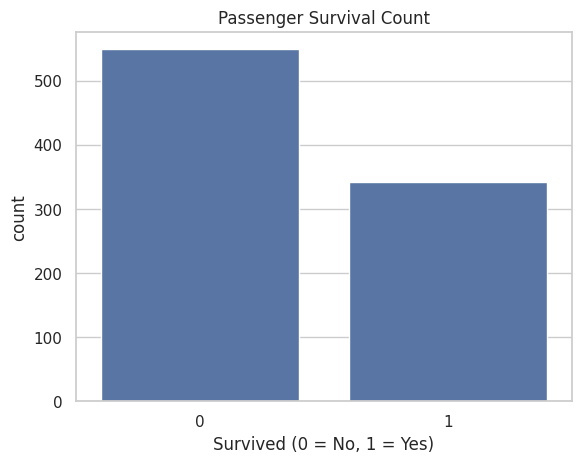

In [33]:
sns.countplot(data=data, x="survived")
plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.show()

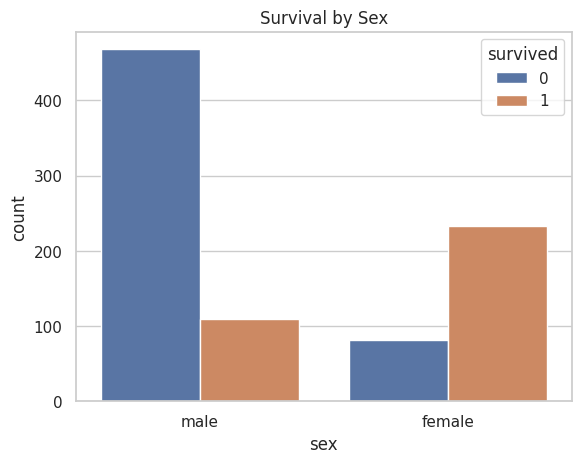

In [34]:
sns.countplot(data=data, x="sex", hue="survived")
plt.title("Survival by Sex")
plt.show()

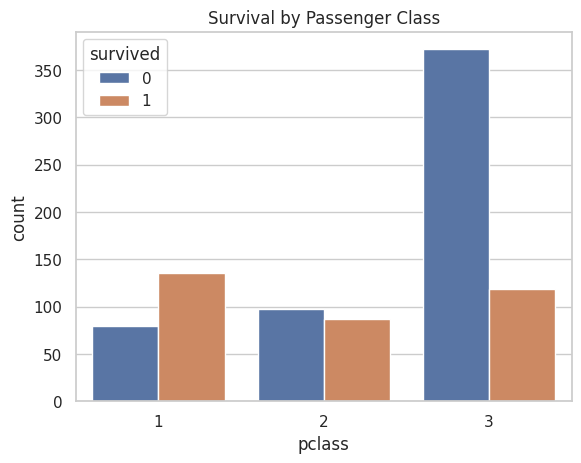

In [35]:
sns.countplot(data=data, x="pclass", hue="survived")
plt.title("Survival by Passenger Class")
plt.show()

## 7. Preprocess features

In [36]:
numeric_features = ["age", "sibsp", "parch", "fare", "family_size", "is_alone"]
categorical_features = ["pclass", "sex", "embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])
print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## 8. Split into training and testing sets

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 712
Testing rows: 179


## 9. Train Logistic Regression model



In [38]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

base_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])


parameter_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    base_pipeline,
    param_grid=parameter_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

model = grid_search.best_estimator_
print("Best parameters:", grid_search.best_params_)
print("Best mean CV accuracy:", round(grid_search.best_score_, 4))
print("Final model trained using training data only.")

Best parameters: {'classifier__C': 0.1, 'classifier__class_weight': None}
Best mean CV accuracy: 0.8006
Final model trained using training data only.


## 10. Predict on test data

In [39]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

display(pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Predicted survival probability": y_probability.round(3)
}).head(10))

,Actual,Predicted,Predicted survival probability
0,0,0,0.128
1,0,0,0.121
2,1,0,0.183
3,0,0,0.081
4,1,1,0.687
5,1,1,0.539
6,1,1,0.673
7,0,0,0.264
8,0,0,0.413
9,0,0,0.268


## 11. Evaluate the model

In [40]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability), 4))

Accuracy: 0.8212
Precision: 0.8136
Recall: 0.6957
F1-score: 0.75
ROC-AUC: 0.8499



- Accuracy: proportion of all predictions that are correct.
- Precision: among predicted survivors, the proportion who actually survived.
- Recall: among actual survivors, the proportion identified by the model.
- F1-score: harmonic balance of precision and recall.
- ROC-AUC: ability to separate the two classes across different thresholds.

## 12. Confusion matrix

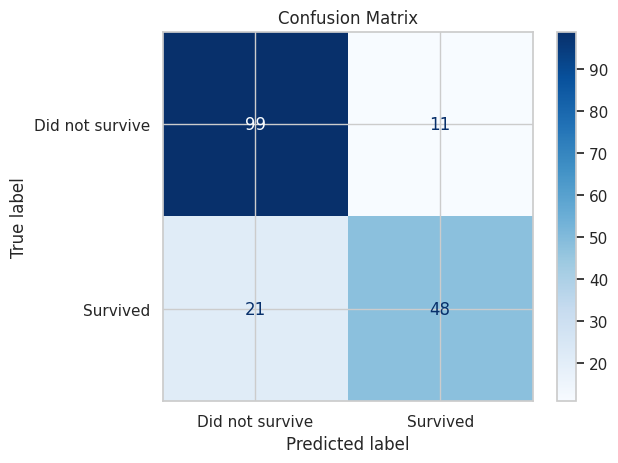

In [41]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Confusion Matrix")
plt.show()

## 13. ROC curve

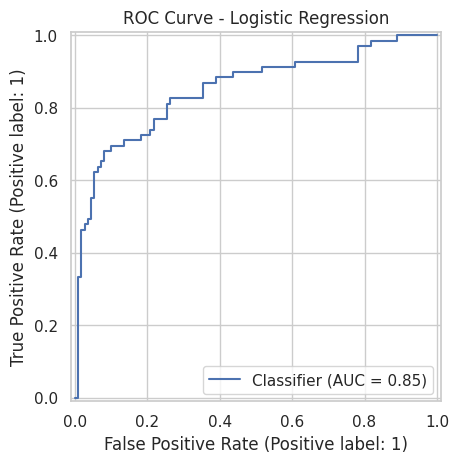

In [42]:
RocCurveDisplay.from_predictions(y_test, y_probability)
plt.title("ROC Curve - Logistic Regression")
plt.show()

## 14. Predict for a new passenger

In [43]:
new_passenger = pd.DataFrame([{
    "pclass": 3,
    "sex": "male",
    "age": 25,
    "sibsp": 0,
    "parch": 0,
    "fare": 8.05,
    "embarked": "S",
    "family_size": 1,
    "is_alone": 1
}])

prediction = model.predict(new_passenger)[0]
probability = model.predict_proba(new_passenger)[0][1]

print("Predicted class:", prediction)
print(f"Estimated survival probability: {probability:.2%}")
if prediction == 1:
    print("Prediction: Passenger is predicted to survive.")
else:
    print("Prediction: Passenger is predicted not to survive.")

Predicted class: 0
Estimated survival probability: 12.87%
Prediction: Passenger is predicted not to survive.


## 15. Save selected dataset

In [44]:
data.to_csv("Titanic_Logistic_Regression_Data.csv", index=False)
print("Saved as Titanic_Logistic_Regression_Data.csv")

Saved as Titanic_Logistic_Regression_Data.csv


## 15. Class balance and baseline comparison

In [45]:
class_counts = y.value_counts()
class_percentages = (y.value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"Count": class_counts, "Percentage": class_percentages}))

majority_class = y_train.mode()[0]
baseline_pred = np.full(len(y_test), majority_class)
baseline_accuracy = accuracy_score(y_test, baseline_pred)
model_accuracy = accuracy_score(y_test, y_pred)

print(f"Majority class: {majority_class}")
print(f"Baseline accuracy: {baseline_accuracy:.4f} ({baseline_accuracy:.2%})")
print(f"Logistic Regression accuracy: {model_accuracy:.4f} ({model_accuracy:.2%})")
print(f"Improvement over baseline: {(model_accuracy-baseline_accuracy):.4f}")

,Count,Percentage
survived,,
0,549,61.62
1,342,38.38


Majority class: 0
Baseline accuracy: 0.6145 (61.45%)
Logistic Regression accuracy: 0.8212 (82.12%)
Improvement over baseline: 0.2067


## 16. Confusion matrix counts and specificity

- **True Positive (TP):** correctly predicted survivor.
- **True Negative (TN):** correctly predicted non-survivor.
- **False Positive (FP):** predicted survivor, but passenger did not survive.
- **False Negative (FN):** predicted non-survivor, but passenger survived.


In [46]:
from sklearn.metrics import confusion_matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp) if (tn + fp) else 0

print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")
print(f"Specificity = {specificity:.4f}")

TN = 99
FP = 11
FN = 21
TP = 48
Specificity = 0.9000


## 17. Full classification report

In [47]:
print(classification_report(
    y_test, y_pred,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))

                 precision    recall  f1-score   support

Did not survive       0.82      0.90      0.86       110
       Survived       0.81      0.70      0.75        69

       accuracy                           0.82       179
      macro avg       0.82      0.80      0.81       179
   weighted avg       0.82      0.82      0.82       179



## 18. Threshold comparison (0.3, 0.5, 0.7)
Changing the threshold changes how many passengers are classified as survivors. Lower thresholds usually increase recall, while higher thresholds often increase precision.

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

threshold_rows = []
for threshold in [0.3, 0.5, 0.7]:
    threshold_pred = (y_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Predicted positive": int(threshold_pred.sum()),
        "Accuracy": accuracy_score(y_test, threshold_pred),
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1-score": f1_score(y_test, threshold_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

,Threshold,Predicted positive,Accuracy,Precision,Recall,F1-score
0,0.3,87,0.7654,0.6552,0.8261,0.7308
1,0.5,59,0.8212,0.8136,0.6957,0.7500
2,0.7,29,0.7542,0.9310,0.3913,0.5510


## 19. Sigmoid function plot

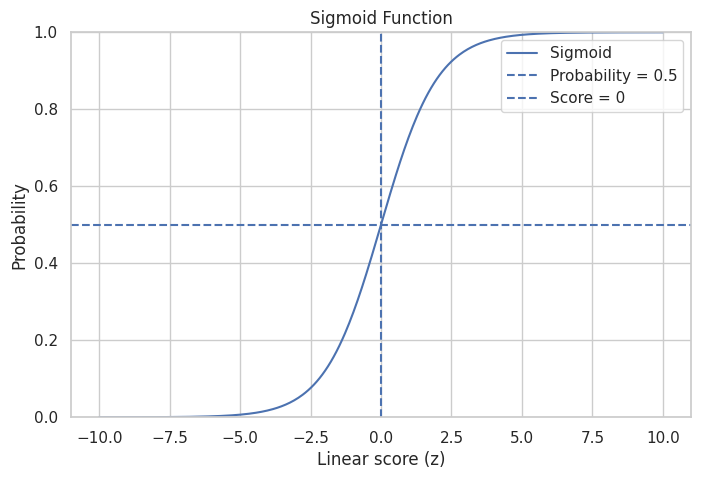

In [49]:
z = np.linspace(-10, 10, 400)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid, label="Sigmoid")
plt.axhline(0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(0, linestyle="--", label="Score = 0")
plt.title("Sigmoid Function")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

## 20. Decision behaviour plot
This plot shows how predicted survival probability changes with age for two example passengers while the other features are held fixed.

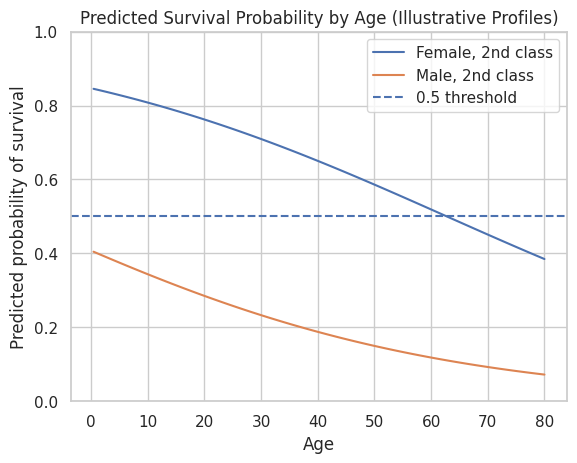

In [50]:
age_range = np.linspace(data["age"].min(), data["age"].max(), 120)
example_profiles = []
for sex_value in ["female", "male"]:
    profile = pd.DataFrame({
        "pclass": 2,
        "sex": sex_value,
        "age": age_range,
        "sibsp": 0,
        "parch": 0,
        "fare": data["fare"].median(),
        "embarked": data["embarked"].mode()[0],
        "family_size": 1,
        "is_alone": 1
    })
    probs = model.predict_proba(profile)[:, 1]
    plt.plot(age_range, probs, label=f"{sex_value.title()}, 2nd class")

plt.axhline(0.5, linestyle="--", label="0.5 threshold")
plt.title("Predicted Survival Probability by Age (Illustrative Profiles)")
plt.xlabel("Age")
plt.ylabel("Predicted probability of survival")
plt.ylim(0, 1)
plt.legend()
plt.grid(True)
plt.show()

## 21. Train vs test performance

In [51]:
train_pred = model.predict(X_train)
test_pred = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Testing accuracy: {test_accuracy:.4f}")
print(f"Train-test gap: {train_accuracy-test_accuracy:.4f}")

Training accuracy: 0.8020
Testing accuracy: 0.8212
Train-test gap: -0.0193


## 22. Model coefficients and interpretation

In [52]:
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": transformed_feature_names,
    "Coefficient": fitted_classifier.coef_[0]
}).sort_values("Coefficient", ascending=False)

print("Intercept:", fitted_classifier.intercept_[0])
display(coefficients.round(4))

Intercept: 0.08069938141416282


,Feature,Coefficient
9,categorical__sex_female,1.0433
6,categorical__pclass_1,0.6236
3,numeric__fare,0.2209
12,categorical__embarked_Q,0.1749
7,categorical__pclass_2,0.1028
11,categorical__embarked_C,0.0835
2,numeric__parch,-0.0559
4,numeric__family_size,-0.1925
1,numeric__sibsp,-0.2442
13,categorical__embarked_S,-0.2568


## 23. Decision log
- **Dataset:** Titanic passenger records were selected because survival is a binary target.
- **Features:** Passenger class, sex, age, family-related counts, fare and embarkation port were selected as plausible predictors. Family size and travelling-alone indicators were engineered from SibSp and Parch.
- **Missing values:** Median imputation was used for numerical values because it is less sensitive to extreme values; most-frequent imputation was used for categorical values.
- **Encoding:** One-Hot Encoding was used for categories so the model does not assume an artificial numeric order.
- **Scaling:** Numerical features were standardized to support stable model fitting.
- **Split:** An 80:20 stratified split preserves the class proportions in train and test sets.
- **Tuning:** Hyperparameters were selected using 5-fold cross-validation on training data only; the test set was kept for final evaluation.
- **Limitations:** Historical survival patterns do not guarantee outcomes. The dataset may contain selection bias, and the model should not be used for real-world safety decisions.

## 24. Conclusion
A Logistic Regression model was trained to predict Titanic passenger survival using selected passenger information and engineered family features. Missing data was imputed, categorical data was encoded, numerical features were scaled, and the model was tuned using cross-validation on the training set. Its performance was evaluated on a separate test set using multiple metrics and compared with a majority-class baseline. Threshold analysis shows the trade-off between precision and recall. The model is an estimate based on historical data and has limitations.